# Week 3: Exploratory Data Analysis and Visualization in Agribusiness

This notebook performs EDA on the cleaned Crop-Wise Area, Production and Yield 
(APY) dataset from Week 2 (450,350 rows, with `is_outlier` and `crop_failure` 
flags). The goal is to identify genuine trends and patterns in crop yield, 
area-production relationships, and yield over time - while being careful to 
avoid the all-crops-combined mistake that distorted early results.

## 1. Load the Cleaned Dataset
Reusing the cleaned, flagged dataset from Week 2 rather than re-cleaning from scratch.

In [1]:
import pandas as pd

df_clean = pd.read_csv('cleaned_apy_data.csv')
print(df_clean.shape)
df_clean.head()

(450350, 18)


,id,year,state_name,state_code,district_name,district_code,crop_name,crop_code,crop_type,season,area,area_unit,production,production_unit,yield,yield_unit,is_outlier,crop_failure
0,0,1997-1998,Andhra Pradesh,28,Ananthapuramu,502,Arhar/Tur,202.0,Pulses,Kharif,21400.0,Hectare,2600.0,Tonnes,0.121,Tonnes/Hectare,False,False
1,1,1997-1998,Andhra Pradesh,28,Ananthapuramu,502,Bajra,103.0,Cereals,Kharif,1400.0,Hectare,500.0,Tonnes,0.357,Tonnes/Hectare,False,False
2,2,1997-1998,Andhra Pradesh,28,Ananthapuramu,502,Castor Seed,1002.0,Oilseeds,Kharif,1000.0,Hectare,100.0,Tonnes,0.100,Tonnes/Hectare,False,False
3,3,1997-1998,Andhra Pradesh,28,Ananthapuramu,502,Cotton(Lint),1101.0,Fiber Crops,Kharif,7300.0,Hectare,9400.0,Tonnes,1.288,Tonnes/Hectare,False,False
4,4,1997-1998,Andhra Pradesh,28,Ananthapuramu,502,Dry Chillies,502.0,Spices,Kharif,3700.0,Hectare,7100.0,Tonnes,1.919,Tonnes/Hectare,False,False


## 2. Summary Statistics - All Crops Combined

In [2]:
print(df_clean['yield'].describe())

count    450350.000000
mean         69.610938
std         866.462944
min           0.000000
25%           0.579000
50%           1.070000
75%           2.586000
max       43958.333000
Name: yield, dtype: float64


**Finding:** mean (69.6) is far higher than the median (1.07), indicating strong 
right-skew - a sign that mixing all crops into one statistic is misleading. 
Confirmed below: Coconut's mean yield (8,974.7) is over 150x higher than the 
next-highest crop, explaining the distortion.

In [9]:
crop_stats = df_clean.groupby('crop_name')['yield'].agg(['mean', 'std', 'median'])
print(crop_stats.sort_values('mean', ascending=False).head(10))

                  mean          std     median
crop_name                                     
Coconut    8974.701796  4852.356511  8140.5480
Sugarcane    58.727913    61.008546    56.1930
Banana       30.694218    21.112367    26.0870
Papaya       29.238914    36.672821    15.7670
Tapioca      19.433170    14.115249    13.0000
Grapes       19.229891    10.374635    20.9240
Pineapple    14.087128     5.774319    14.7860
Onion        13.539762    44.261898    11.7620
Potato       12.898751     8.285932    10.4910
Cabbage      12.599987    17.127751     8.8095


## 3. Yield Distributions by Crop
Visualizing staple crops (Wheat, Rice, Maize, Sugarcane) separately, excluding 
flagged outlier and crop-failure rows, to see each crop's true distribution shape.

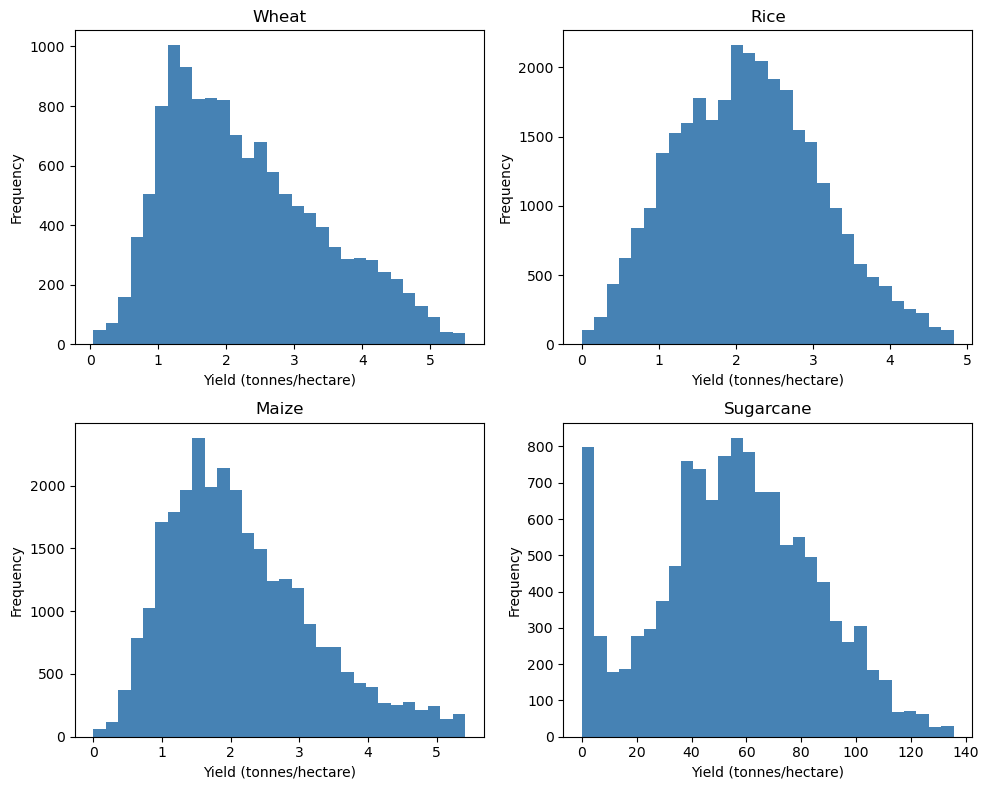

In [23]:
import matplotlib.pyplot as plt

staples = ['Wheat', 'Rice', 'Maize', 'Sugarcane']
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for i, crop in enumerate(staples):
    data = df_clean[(df_clean['crop_name'] == crop) & (~df_clean['is_outlier']) & (~df_clean['crop_failure'])]['yield']
    axes[i].hist(data, bins=30, color='steelblue')
    axes[i].set_title(crop)
    axes[i].set_xlabel('Yield (tonnes/hectare)')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

**Finding:** Wheat, Rice, and Maize show clean right-skewed bell shapes once 
flagged rows are excluded. Sugarcane is different - it remains bimodal (two 
humps: a cluster near 0 and a separate bell around 40-80), even after removing 
flagged rows. This spike is investigated below.

In [24]:
print(df_clean[(df_clean['crop_name']=='Sugarcane') & (df_clean['yield']<5)]['state_name'].value_counts().head())

state_name
Chhattisgarh        361
Madhya Pradesh      153
Meghalaya           151
Mizoram              51
Himachal Pradesh     38
Name: count, dtype: int64


**Finding:** the near-zero Sugarcane cluster is concentrated in Chhattisgarh, 
Madhya Pradesh, and northeastern hill states - regions associated with rain-fed 
rather than irrigated cultivation. This suggests a genuine regional productivity 
divide, not a data error.

## 4. Correlation Analysis
Checking whether area and production move together - first across all crops combined.

In [25]:
correlation = df_clean['area'].corr(df_clean['production'])
print(correlation)

0.042448797943654644


**Finding:** correlation is only 0.04 - nearly zero - which is counterintuitive. 
Testing whether this is another all-crops-mixed artifact, following the same 
pattern seen in Sections 2-3.

In [26]:
wheat_data = df_clean[df_clean['crop_name'] == 'Wheat']
correlation_wheat = wheat_data['area'].corr(wheat_data['production'])
print(correlation_wheat)

0.9361985610261705


**Finding:** Wheat alone shows correlation of 0.94 - a huge difference from the 
0.04 mixed-crop figure. Confirms that crop-level segmentation is necessary for 
correlation too, not just for distributions.

In [27]:
for crop in ['Wheat', 'Rice', 'Maize', 'Sugarcane']:
    data = df_clean[df_clean['crop_name'] == crop]
    corr = data['area'].corr(data['production'])
    print(crop, ':', corr)

Wheat : 0.9361985610261705
Rice : 0.8983093050117887
Maize : 0.8515434445975194
Sugarcane : 0.9289311267012251


**Finding:** all four staple crops show strong correlation (0.85-0.94), confirming 
this is a general pattern, not unique to Wheat.

## 5. Yield Trend Over Time
Checking whether yield has improved over the 1997-2023 period - first across all crops combined.

In [28]:
df_clean['year_start'] = df_clean['year'].str[:4].astype(int)

yearly_avg = df_clean[~df_clean['is_outlier'] & ~df_clean['crop_failure']].groupby('year_start')['yield'].mean()
print(yearly_avg)

year_start
1997    45.590419
1998    46.681034
1999    47.831949
2000    58.253412
2001    57.713575
2002    66.685056
2003    64.473484
2004    68.947193
2005    76.116367
2006    78.540129
2007    69.676309
2008    83.725009
2009    86.279485
2010    68.989804
2011    88.719514
2012    66.068645
2013    77.075403
2014    84.288646
2015    78.863187
2016    71.562607
2017    73.693502
2018    72.929946
2019    70.486375
2020    49.549362
2021    59.165220
2022    81.717569
Name: yield, dtype: float64


**Finding:** the mixed-crop yearly average rises from ~45 to ~88, which looks like 
a dramatic improvement - but given the lessons above, this is likely a crop-mix 
artifact (e.g., more high-yield crops like Coconut being reported in later years), 
not a genuine productivity trend. Isolating a single crop to verify.

In [29]:
wheat_yearly = df_clean[(df_clean['crop_name']=='Wheat') & (~df_clean['is_outlier']) & (~df_clean['crop_failure'])].groupby('year_start')['yield'].mean()
print(wheat_yearly)

year_start
1997    1.904144
1998    1.875804
1999    2.100648
2000    1.931687
2001    2.030374
2002    1.912311
2003    1.976954
2004    1.915455
2005    1.843861
2006    2.029185
2007    2.113884
2008    2.075866
2009    2.078257
2010    2.261747
2011    2.454423
2012    2.499543
2013    2.446372
2014    2.150225
2015    2.314572
2016    2.635103
2017    2.694554
2018    2.695315
2019    2.700430
2020    2.787861
2021    2.707884
2022    2.726162
Name: yield, dtype: float64


**Finding:** Wheat alone shows a real, more modest trend - 1.90 to 2.73 
tonnes/hectare (~40% over 25 years) - consistent with genuine agricultural 
improvement (better seed varieties, irrigation access), not crop-mix noise.

## 6. Visualizing the Wheat Trend

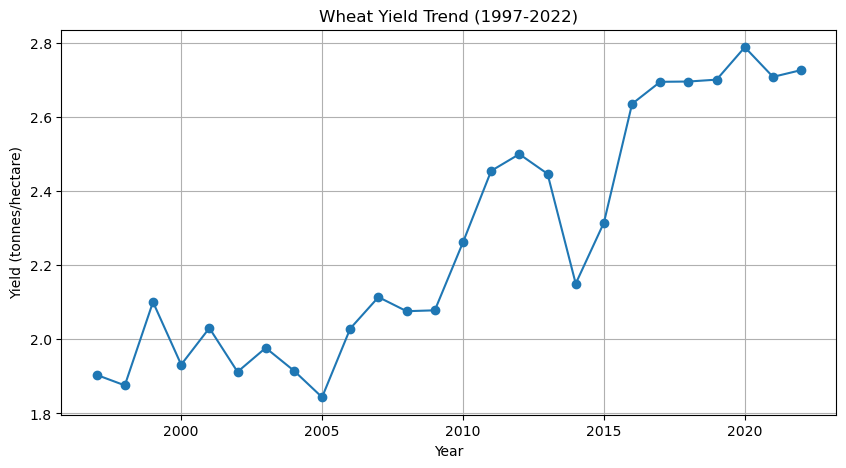

In [30]:
wheat_yearly.plot(kind='line', marker='o', figsize=(10,5))
plt.title('Wheat Yield Trend (1997-2022)')
plt.xlabel('Year')
plt.ylabel('Yield (tonnes/hectare)')
plt.grid(True)
plt.show()

**Finding:** the trend is not smooth - a flat period (1997-2009), a rise 
(2010-2012), a sharp dip in 2014, then the steepest sustained rise (2015-2020). 
The 2014 dip is investigated below.

## 7. Investigating the 2014 Dip

In [31]:
dip_year = df_clean[(df_clean['crop_name']=='Wheat') & (df_clean['year_start']==2014) & (~df_clean['is_outlier']) & (~df_clean['crop_failure'])]
print(dip_year.groupby('state_name')['yield'].mean().sort_values())

state_name
Andhra Pradesh                                  1.019000
Sikkim                                          1.050000
Telangana                                       1.154800
Assam                                           1.199308
Maharashtra                                     1.200621
Karnataka                                       1.290000
Odisha                                          1.440750
Jharkhand                                       1.492843
Uttarakhand                                     1.542846
Meghalaya                                       1.566800
Bihar                                           1.676263
Chhattisgarh                                    1.744769
Nagaland                                        1.823333
Himachal Pradesh                                1.846833
Uttar Pradesh                                   2.065133
The Dadra And Nagar Haveli And Daman And Diu    2.079000
Tripura                                         2.213500
Arunachal Pradesh   

**Finding:** the 2014 dip was driven almost entirely by Uttar Pradesh (India's 
largest wheat-producing state), where yield fell from 3.22 to 2.07 tonnes/hectare 
before recovering by 2016. Punjab and Madhya Pradesh remained stable. This shows 
that national yield figures can be disproportionately sensitive to conditions in 
a single dominant-producing state.